# Multivariable calculus 1: Functions of two variables

*Learning path: multivariable calculus, part 1 of 7.* [Index](README.md) · Previous: [Held, simplify, eval](00-held-simplify-eval.ipynb) · Next: [Partial derivatives and the gradient](02-partial-derivatives-and-gradient.ipynb)

A hiking map shows a mountain on flat paper. It does it with **contour lines**: each line joins the points at one
height. Hikers read steepness from how close the lines are, and peaks and passes from their shapes. This lesson is
about that idea. A function of two variables $f(x, y)$ is a landscape, and we will learn to see it two ways: as a
surface in 3D, and as a map of level curves in the plane.

**Who this is for.** Students starting multivariable calculus (Calculus III). You should know:

* functions of one variable and their graphs ([foundations 3](../foundations/03-functions-and-graphs.ipynb));
* derivatives of one variable ([foundations 7](../foundations/07-calculus.ipynb));
* the equation of a circle and an ellipse ([foundations 9](../foundations/09-geometry-and-conics.ipynb)).

**What you will be able to do afterwards:**

1. evaluate a function of two variables and describe its domain;
2. draw its graph as a surface and its level curves as a contour map, and go back and forth between the two;
3. recognise a peak, a pit, a pass (saddle) and a ridge on a contour map;
4. read steepness from the spacing of level curves.

Plan about 45 minutes. Each section ends with a **Try this** for the cell below it; exercises, hints and answers
are at the end. Galileo draws and checks; the thinking is yours.

## 1. One output, two inputs

A function of two variables takes a point $(x, y)$ and returns one number. The temperature on a metal plate, the
height of the ground, the profit from selling $x$ chairs and $y$ tables: each is a function $f(x, y)$.

In Galileo, define one with `:=` and call it like any function:

In [1]:
f(x, y) := 9 - x^2 - y^2
f(0, 0)
f(1, 2)
f(3, 0)

f(x, y) := 9-x^2-y^2
9
4
0

Before running a cell, predict its answers. Here $f(0,0) = 9$, $f(1, 2) = 9 - 1 - 4 = 4$ and $f(3, 0) = 0$. The
**domain** is the set of points where $f$ makes sense; this $f$ is defined everywhere. A function like
$g(x, y) = \sqrt{4 - x^2 - y^2}$ is only defined where $x^2 + y^2 \le 4$, the disk of radius 2.

**Try this.** Define `h(x, y) := log(x - y)` and evaluate it at $(3, 1)$. Then describe its domain in words: which
points $(x, y)$ are allowed? Check with a point that is not allowed, such as $(1, 3)$; what does Galileo return?

## 2. The graph: a surface

The graph of $f$ is the set of points $(x, y, z)$ with $z = f(x, y)$, a surface above (or below) the plane. For our
$f$, a dome:

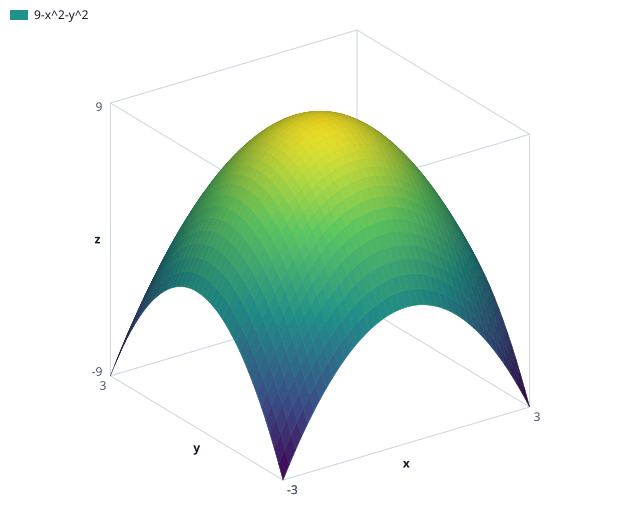

> `plot3d`: Plots the surface z = f(x, y) over a <= x <= b, c <= y <= d.

In [2]:
plot3d(9 - x^2 - y^2, x, -3, 3, y, -3, 3)

How to read the call: `plot3d(f, x, from, to, y, from, to)` samples $f$ on a grid over the rectangle
$-3 \le x \le 3$, $-3 \le y \le 3$ and draws the heights. In JupyterLab you can drag to turn it.

A good way to understand a surface is to **slice** it. Fix $y = 0$ and you get a curve in $x$ alone, the
cross-section above the $x$-axis:

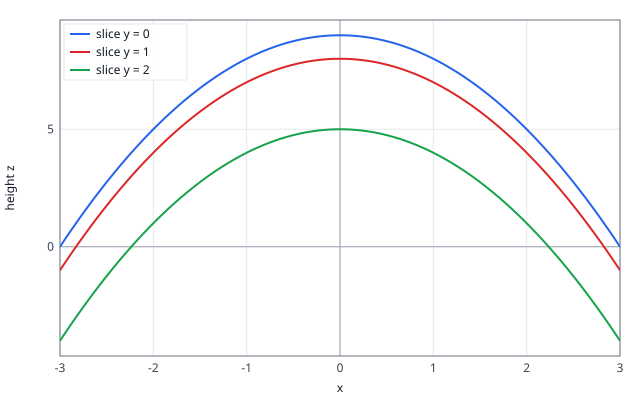

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
p = plot(9 - x^2, 9 - x^2 - 1, 9 - x^2 - 4, x, -3, 3);
labels(legend(p, "slice y = 0", "slice y = 1", "slice y = 2"), "x", "height z")

Each curve is one slice $y = c$ of the dome: a parabola, lower when $|c|$ is larger. Slicing turns a two-variable
problem into one-variable problems you already know how to handle. The next lesson builds partial derivatives on
exactly this idea.

**Try this.** Draw the slices $x = 0$, $x = 1$, $x = 2$ of $f(x, y) = x^2 - y^2$ (plot in the variable $y$). Then
the slices $y = 0, 1, 2$ (in $x$). One family opens up, the other down. What does that tell you about the shape of
the surface? Check with `plot3d`.

## 3. Level curves: the map

Now slice **horizontally**: fix the height $f(x, y) = c$. For the dome, $9 - x^2 - y^2 = c$ means
$x^2 + y^2 = 9 - c$, a circle of radius $\sqrt{9 - c}$. Each height gives one circle; together they are the contour
map:

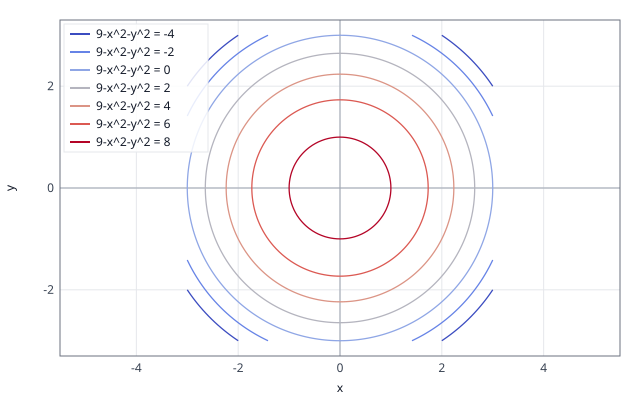

> Level curves of 9-x^2-y^2: each curve joins the points where f has one value (the legend gives it), from blue (low) to red (high). Where curves crowd together f changes fast; the gradient crosses them at right angles.

In [4]:
contour(9 - x^2 - y^2, x, -3, 3, y, -3, 3)

How to read it: `contour(f, x, from, to, y, from, to)` draws the curves $f = c$ for round values $c$, colored from
blue (low) to red (high); the legend gives each value. The center is the top (red), the outer circles are low.

Compare the two pictures: the contour map is the view from above, with the heights written on the lines. You lose
nothing, and it fits on flat paper.

You can choose the levels yourself, as a list:

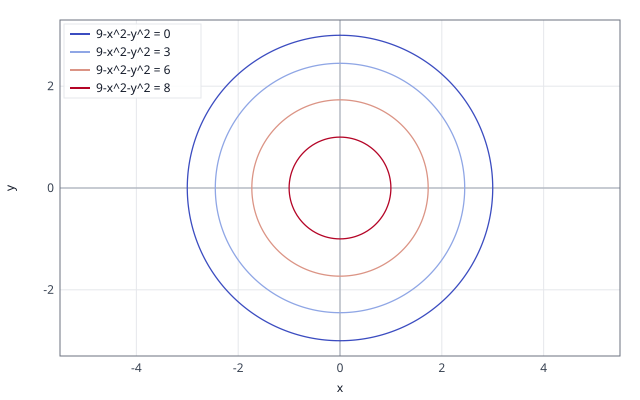

> Level curves of 9-x^2-y^2: each curve joins the points where f has one value (the legend gives it), from blue (low) to red (high). Where curves crowd together f changes fast; the gradient crosses them at right angles.

In [5]:
contour(9 - x^2 - y^2, x, -3, 3, y, -3, 3, [0 3 6 8])

The circles for $c = 0, 3, 6, 8$ have radii $3$, $\sqrt 6 \approx 2.45$, $\sqrt 3 \approx 1.73$ and $1$. Equal steps in
height, $3$ each, but the circles get **closer** toward the edge. That is the second big idea of a contour map:

> Where level curves crowd together, the surface is steep. Where they are far apart, it is flat.

The dome is flat on top and steep at the edges, as the 3D picture showed.

**Try this.** Work out by hand the level curve $f = 5$ of the dome (which circle?). Add 5 to the list of levels and
check that the new curve has the radius you predicted.

## 4. Peaks, pits and passes

Three landscapes show the shapes you will meet again and again. Look at each contour map and predict the surface
before drawing it.

**A pit** (a bowl): $x^2 + 3y^2$. Its level curves are ellipses around the lowest point.

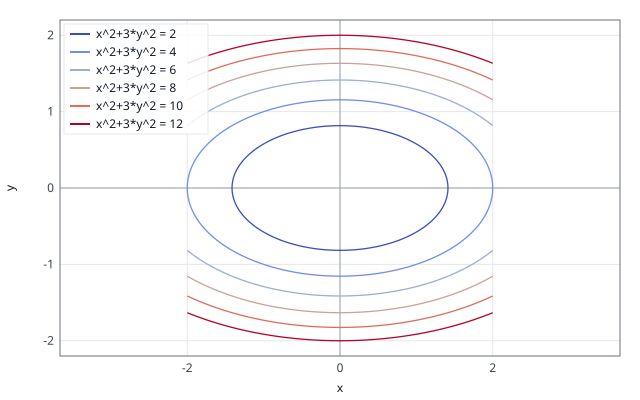

> Level curves of x^2+3*y^2: each curve joins the points where f has one value (the legend gives it), from blue (low) to red (high). Where curves crowd together f changes fast; the gradient crosses them at right angles.

In [6]:
contour(x^2 + 3*y^2, x, -2, 2, y, -2, 2)

The ellipses are narrower in the $y$ direction: height grows three times faster in $y$, so the curves crowd there.

**A pass** (a saddle): $x^2 - y^2$. Its level curves are hyperbolas, and the level $0$ is a pair of crossing lines.

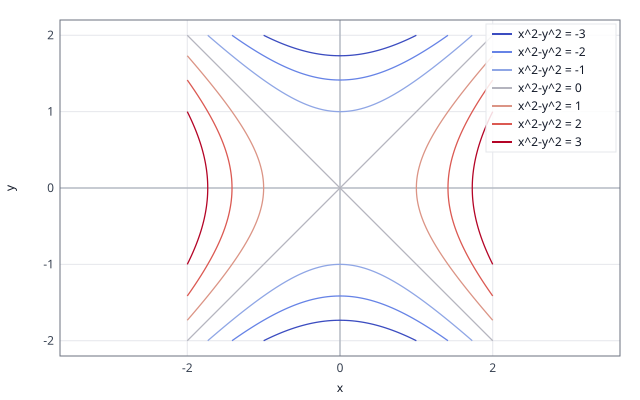

> Level curves of x^2-y^2: each curve joins the points where f has one value (the legend gives it), from blue (low) to red (high). Where curves crowd together f changes fast; the gradient crosses them at right angles.

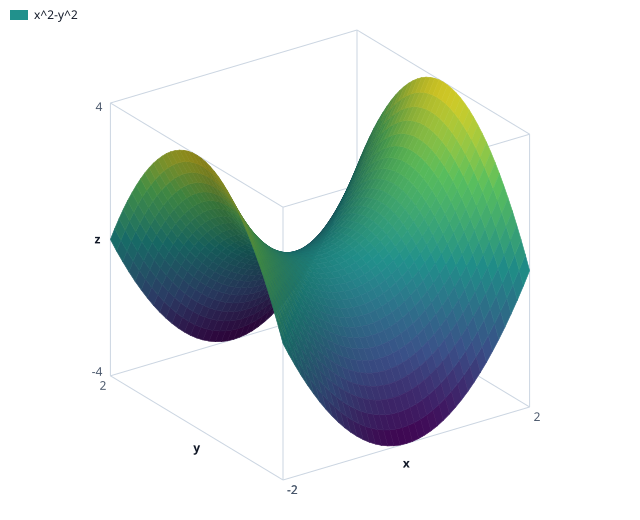

> `plot3d`: Plots the surface z = f(x, y) over a <= x <= b, c <= y <= d.

In [7]:
contour(x^2 - y^2, x, -2, 2, y, -2, 2)
plot3d(x^2 - y^2, x, -2, 2, y, -2, 2)

Walking along the $x$-axis you go **up** on both sides of the origin; along the $y$-axis you go **down**. The origin is
the lowest point of one path and the highest of the other, like a mountain pass, or a saddle on a horse. On a
contour map a pass looks like an X: two level curves crossing.

**Two hills**: $e^{-(x-1)^2 - y^2} + e^{-(x+1)^2 - y^2}$.

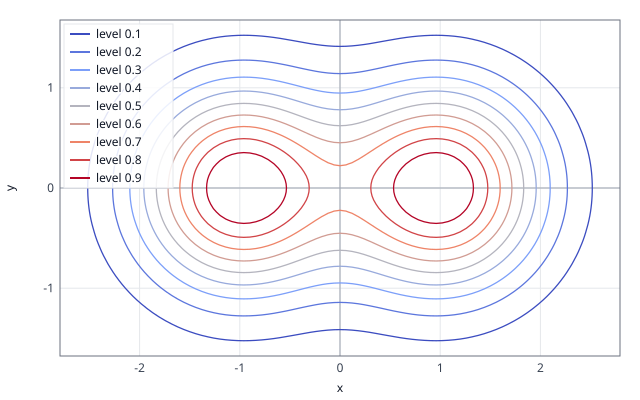

> Level curves of exp(-(x-1)^2-y^2)+exp(-(x+1)^2-y^2): each curve joins the points where f has one value (the legend gives it), from blue (low) to red (high). Where curves crowd together f changes fast; the gradient crosses them at right angles.

In [8]:
contour(exp(-(x-1)^2 - y^2) + exp(-(x+1)^2 - y^2), x, -3, 3, y, -2, 2)

Two sets of closed curves around two peaks, and between them a level curve shaped like a figure eight: it passes
through the saddle point between the hills. Finding such points exactly is lesson 3.

**Try this.** Predict the contour map of $f(x, y) = x + y$ (a tilted plane) and of $f(x, y) = y - x^2$. Draw them.
For the second one, which level curve passes through the origin?

## 5. Level curves of curves: implicit equations

Every equation $F(x, y) = 0$ is the level curve $0$ of the function $F$. That is how circles, ellipses and hyperbolas
from [foundations 9](../foundations/09-geometry-and-conics.ipynb) fit in here. `implicitplot` draws just that one
curve:

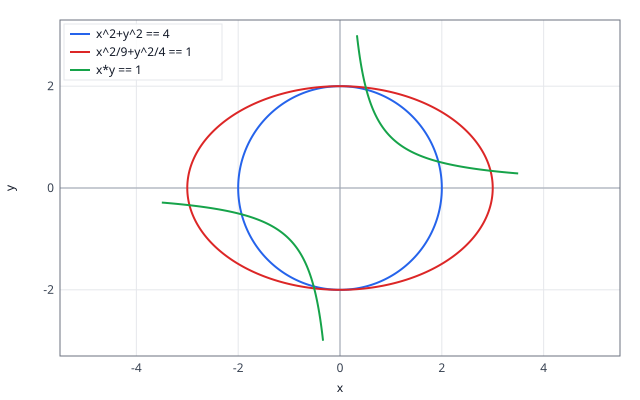

> `implicitplot`: Draws the curve F(x, y) = 0, or an equation such as x^2 + y^2 == 1, in the window x0..x1, y0..y1 (equal scales).

In [9]:
implicitplot([x^2 + y^2 == 4, x^2/9 + y^2/4 == 1, x*y == 1], x, -3.5, 3.5, y, -3, 3)

How to read the call: a list of equations, then the ranges. Galileo marks where the two sides are equal. This is
the same as `contour` with a single level, and you can combine pictures with `show`:

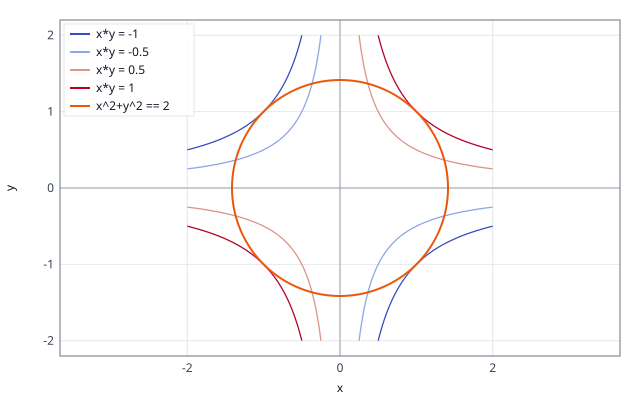

> `show`: Overlays plots: all 2D, or all 3D.

In [10]:
show(contour(x*y, x, -2, 2, y, -2, 2, [-1 -0.5 0.5 1]), implicitplot(x^2 + y^2 == 2, x, -2, 2, y, -2, 2))

Here the hyperbolas $xy = c$ cross the circle $x^2 + y^2 = 2$. Ask yourself: what is the largest value of $xy$ on
the circle? The level curve $xy = 1$ just touches the circle; higher levels miss it. Touching level curves will be
the key idea of [lesson 4](04-lagrange-multipliers.ipynb) on optimization with constraints.

**Try this.** Draw the level curves of $f(x, y) = x + 2y$ together with the circle $x^2 + y^2 = 5$. Which level
of $f$ just touches the circle, and where?

## 6. Three variables: level surfaces

A function $f(x, y, z)$ of three variables would need four dimensions for its graph. Instead we look at its **level
surfaces** $f = c$. The temperature around a hot point $T = 1/(x^2 + y^2 + z^2)$ has spheres as level surfaces. The
sphere of radius 2 is drawn with its usual parametrization:

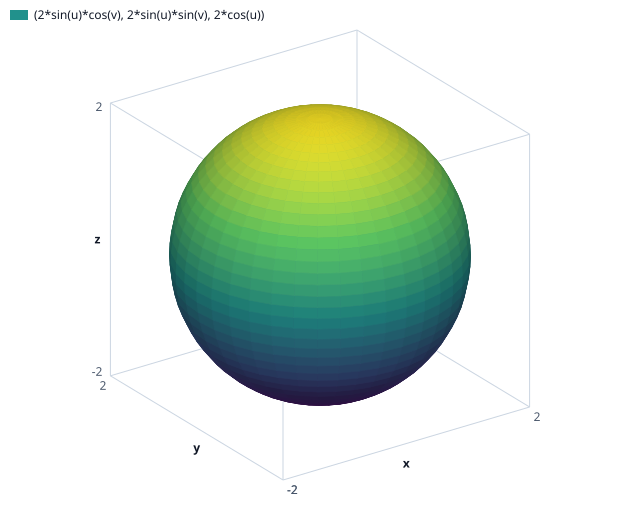

> `surface`: Plots a parametric surface.

In [11]:
surface(2*sin(u)*cos(v), 2*sin(u)*sin(v), 2*cos(u), u, 0, pi, v, 0, 2*pi)

`surface(x(u,v), y(u,v), z(u,v), u, ..., v, ...)` draws a surface from two parameters, here the angle $u$ from the
north pole and the angle $v$ around the axis (the same angles as latitude and longitude, measured differently).
We will use parametrized surfaces again for flux in [lesson 7](07-the-big-theorems.ipynb).

## Exercises

1. **Domains.** Describe the domain of $f(x, y) = \sqrt{y - x^2}$ and draw its boundary with `implicitplot`. Is the
   boundary part of the domain?
2. **Read the map.** Without drawing, sketch the level curves $f = 0, 1, 4$ of $f(x, y) = x^2 + y^2$ and of
   $g(x, y) = \sqrt{x^2 + y^2}$. Both have circles. How do the two maps differ, and what does that say about the
   shapes (a bowl and a cone)? Then check with `contour`.
3. **Match.** Which function has which map? (a) $\sin x \sin y$, (b) $x^2 - 2y$, (c) $e^{-x^2 - y^2}$. Draw
   each on $-3 \le x, y \le 3$ and describe what you see in one sentence each: peaks, pits, saddles, parallel curves.
4. **Steepness.** On the map of $f(x, y) = 9 - x^2 - y^2$ with levels $0, 1, \ldots, 8$, measure (from the radii)
   the distance between the curves $8$ and $7$, and between $1$ and $0$. Which part of the dome is steeper, and by
   about how much?
5. **Saddle hunting.** The function $f(x, y) = x^3 - 3xy + y^3$ has one saddle and one pit. Find them roughly from
   a contour map on $-2 \le x, y \le 2$. (Lesson 3 finds them exactly.)

## Hints and answers

* **Section 1, Try this.** $\log(3 - 1) = \log 2$. The domain is $x > y$: the half-plane below the line $y = x$.
  At $(1, 3)$ the argument is negative: `log(-2)` has no real value, and Galileo leaves it as a complex logarithm or
  an unevaluated expression.
* **Section 2, Try this.** The $x$-slices $-y^2 + c$ open down, the $y$-slices $x^2 - c$ open up: the surface curves
  up in one direction and down in the other, a saddle.
* **Section 3, Try this.** $9 - x^2 - y^2 = 5$ is the circle $x^2 + y^2 = 4$ of radius 2.
* **Section 4, Try this.** $x + y = c$ gives parallel lines, equally spaced (a plane has the same steepness
  everywhere). $y - x^2 = c$ gives parabolas $y = x^2 + c$; the level $0$ passes through the origin.
* **Section 5, Try this.** The level $5$ touches the circle, at $(1, 2)$: there $x + 2y = 5$, and the line
  $x + 2y = 5$ is tangent to the circle.
* **Exercise 1.** $y \ge x^2$: the region on and above the parabola $y = x^2$; the boundary belongs to it, since
  $\sqrt 0 = 0$ is defined.
* **Exercise 2.** $x^2 + y^2 = c$ has radius $\sqrt c$; $\sqrt{x^2 + y^2} = c$ has radius $c$. With equally spaced
  levels $0, 1, 2, 3, 4$ the bowl's radii are $0, 1, 1.41, 1.73, 2$: the circles crowd together further out, so the
  bowl gets steeper and steeper. The cone's radii are $0, 1, 2, 3, 4$, equally spaced: constant steepness.
* **Exercise 3.** (a) a checkerboard of peaks and pits with saddles between them; (b) parabolas
  $y = (x^2 - c)/2$, all the same shape, shifted; (c) circles around a single peak at the origin.
* **Exercise 4.** The radii are $1$ (level 8), $\sqrt 2$ (level 7), $\sqrt 8$ (level 1), $3$ (level 0). The gaps
  are $0.41$ near the top and $0.17$ near the edge: the edge is about $2.4$ times steeper.
* **Exercise 5.** A pit near $(1, 1)$ and a saddle at $(0, 0)$, where two level curves cross.

## Sources

1. J. Stewart, *Calculus: Early Transcendentals*, 9th ed., Cengage (2020), chapter 14.1.
2. G. Strang and E. Herman, *Calculus Volume 3*, OpenStax (2016), section 4.1. Free at openstax.org.
3. M. Spivak, *Calculus on Manifolds*, Benjamin (1965), chapter 1, for the rigorous picture.